# 05 · Threshold, cost and the one-time holdout check

**Questions this notebook answers**

1. Above which score should a transaction go to step-up, if we want the lowest total cost?
2. How much does that save compared with doing nothing, and what does it mean for customers
   (recall, precision, share of transactions stepped up)?
3. How sensitive are the threshold and the cost to the assumed cost values?
4. Does adding a "decline" tier (approve / step-up / decline) lower cost further?
5. On the untouched holdout, do the CV results hold up?

> **All costs in this notebook are illustrative assumptions, not bank data**
> (`configs/cost.yaml`, accepted by Nat as illustrative on 2026-11-09).

Thresholds are chosen on dev out-of-fold (OOF) predictions only. For each of the 3 CV repeats the
full set of dev OOF scores gives a cost-vs-threshold curve; the curves are averaged and the
minimum is the threshold (pre-registration A2).

In [1]:
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import plots as P
from fraud_e2e.cost import (
    COST_LABEL,
    load_cost_params,
    load_sensitivity_factors,
    load_three_tier_params,
)
from fraud_e2e.cv import load_result, metric_ci
from fraud_e2e.data import load_raw
from fraud_e2e.evaluate import evaluate_holdout
from fraud_e2e.reporting import read_json, write_csv, write_json
from fraud_e2e.splits import attach_splits
from fraud_e2e.threshold import (
    NEAR_OPTIMAL_TOL,
    choose_three_tier,
    choose_threshold,
    export_for_web,
    sensitivity,
    web_grid,
)

P.set_style()
cost = load_cost_params()
three = load_three_tier_params()
final = load_result("final")
final_spec = read_json("p2_modeling")["final_pipeline"]["spec"]
oof = final.oof
print(f"final pipeline spec: {final_spec}")
print(f"cost status: {cost.status}; three-tier status: {three.status}")
pd.Series(cost.numeric(), name="assumed value").to_frame()

final pipeline spec: {'params': {}, 'imbalance': 'none', 'drop': [], 'calibration': None, 'model': 'logreg'}
cost status: accepted; three-tier status: proposed


,assumed value
review_cost_per_alert,5.0
fp_friction_cost,10.0
fn_loss_fraction,1.0
fn_fixed_cost,15.0


## 1. Cost-optimal step-up threshold (two-tier policy)

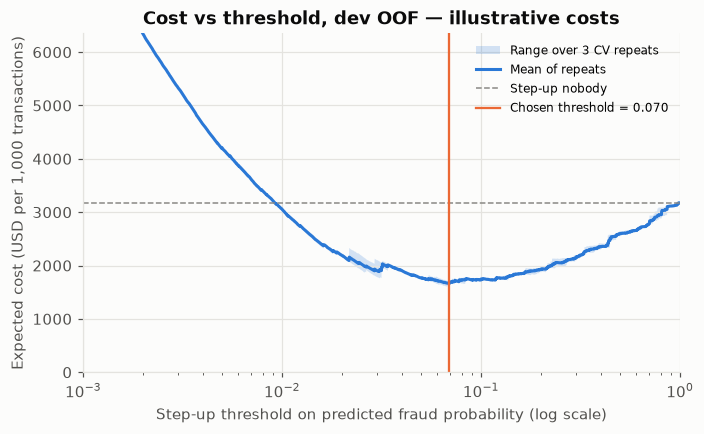

In [2]:
best = choose_threshold(oof, cost)
grid, curves = best.pop("_grid"), best.pop("_curves")
n = best["n_rows"]

fig, ax = P.plt.subplots(figsize=(7, 4))
per1000 = curves / n * 1000
ax.fill_between(
    grid,
    per1000.min(0),
    per1000.max(0),
    color=P.SERIES[0],
    alpha=0.2,
    lw=0,
    label="Range over 3 CV repeats",
)
ax.plot(grid, per1000.mean(0), color=P.SERIES[0], lw=2, label="Mean of repeats")
ax.axhline(
    best["flag_nothing_cost_usd"] / n * 1000, color=P.NEUTRAL, ls="--", lw=1, label="Step-up nobody"
)
ax.axvline(
    best["threshold"], color=P.FRAUD, lw=1.5, label=f"Chosen threshold = {best['threshold']:.3f}"
)
ax.set_xscale("log")
ax.set_xlim(1e-3, 1)
ax.set_ylim(0, best["flag_nothing_cost_usd"] / n * 1000 * 2)
ax.set_xlabel("Step-up threshold on predicted fraud probability (log scale)")
ax.set_ylabel("Expected cost (USD per 1,000 transactions)")
ax.set_title("Cost vs threshold, dev OOF — illustrative costs")
ax.legend(loc="upper right", fontsize=8)
P.save(fig, "p2_cost_curve")
P.plt.show()

In [3]:
display(
    Markdown(f"""
**Chosen threshold: {best["threshold"]:.4f}** (best threshold per repeat:
{", ".join(f"{t:.4f}" for t in best["best_threshold_per_repeat"])}). On the averaged curve,
thresholds from {best["near_optimal_range"][0]:.4f} to {best["near_optimal_range"][1]:.4f} are within
{100 * NEAR_OPTIMAL_TOL:.0f}% of the minimum cost; the spread of the per-repeat optima is the more
honest measure of how precisely the threshold is known.

| | value |
|---|---|
| Expected cost | **{best["cost_per_1000_txn"]:,.0f} USD per 1,000 transactions** (SD across repeats {best["cost_sd_across_repeats"] / n * 1000:,.0f}) |
| Step-up nobody | {best["flag_nothing_cost_usd"] / n * 1000:,.0f} USD per 1,000 |
| Saving vs step-up nobody | **{100 * best["saving_vs_flag_nothing"]:.1f}%** |
| Recall (fraud caught) | {100 * best["recall"]:.1f}% |
| Precision (alerts that are fraud) | {100 * best["precision"]:.1f}% |
| Share of transactions stepped up | {100 * best["alert_rate"]:.2f}% |

_{COST_LABEL}._
""")
)


**Chosen threshold: 0.0695** (best threshold per repeat:
0.0834, 0.0673, 0.0738). On the averaged curve,
thresholds from 0.0652 to 0.0695 are within
1% of the minimum cost; the spread of the per-repeat optima is the more
honest measure of how precisely the threshold is known.

| | value |
|---|---|
| Expected cost | **1,664 USD per 1,000 transactions** (SD across repeats 54) |
| Step-up nobody | 3,175 USD per 1,000 |
| Saving vs step-up nobody | **47.6%** |
| Recall (fraud caught) | 69.5% |
| Precision (alerts that are fraud) | 23.5% |
| Share of transactions stepped up | 5.01% |

_Illustrative assumed costs (not bank data)._


## 2. Sensitivity to the cost assumptions

Each parameter is multiplied by ×0.5 and ×2 with the others at their base value. For each case the
threshold is re-optimised. "Regret" is the extra cost of keeping the base threshold instead.

In [4]:
factors = load_sensitivity_factors()
sens = sensitivity(oof, cost, factors)
write_csv(sens, "p2_cost_sensitivity")
sens.round(
    {
        "best_threshold": 4,
        "cost_per_1000_txn": 1,
        "cost_per_1000_at_base_threshold": 1,
        "regret_per_1000_txn": 2,
        "recall": 3,
        "precision": 3,
        "alert_rate": 4,
    }
)

,parameter,factor,value,best_threshold,near_optimal_low,near_optimal_high,cost_per_1000_txn,cost_per_1000_at_base_threshold,regret_per_1000_txn,recall,precision,alert_rate
0,(base),1.0,NaN,0.0695,0.065163,0.069502,1663.7,1663.7,0.00,0.695,0.235,0.0501
1,review_cost_per_alert,0.5,2.5,0.0692,0.064565,0.069502,1537.9,1538.3,0.48,0.697,0.235,0.0504
2,review_cost_per_alert,2.0,10.0,0.1180,0.109901,0.133352,1882.5,1914.4,31.95,0.582,0.318,0.0310
3,fp_friction_cost,0.5,5.0,0.0292,0.028510,0.069502,1466.6,1471.8,5.22,0.818,0.138,0.1007
4,fp_friction_cost,2.0,20.0,0.1180,0.111173,0.134586,1938.7,2047.5,108.72,0.582,0.318,0.0310
5,fn_loss_fraction,0.5,0.5,0.1334,0.112720,0.137404,1097.6,1187.8,90.24,0.551,0.339,0.0276
6,fn_loss_fraction,2.0,2.0,0.0292,0.028445,0.029174,2383.3,2615.4,232.10,0.818,0.138,0.1007
7,fn_fixed_cost,0.5,7.5,0.0695,0.066374,0.069502,1625.0,1625.0,0.00,0.695,0.235,0.0501
8,fn_fixed_cost,2.0,30.0,0.0692,0.064714,0.069502,1740.6,1741.2,0.58,0.697,0.235,0.0504


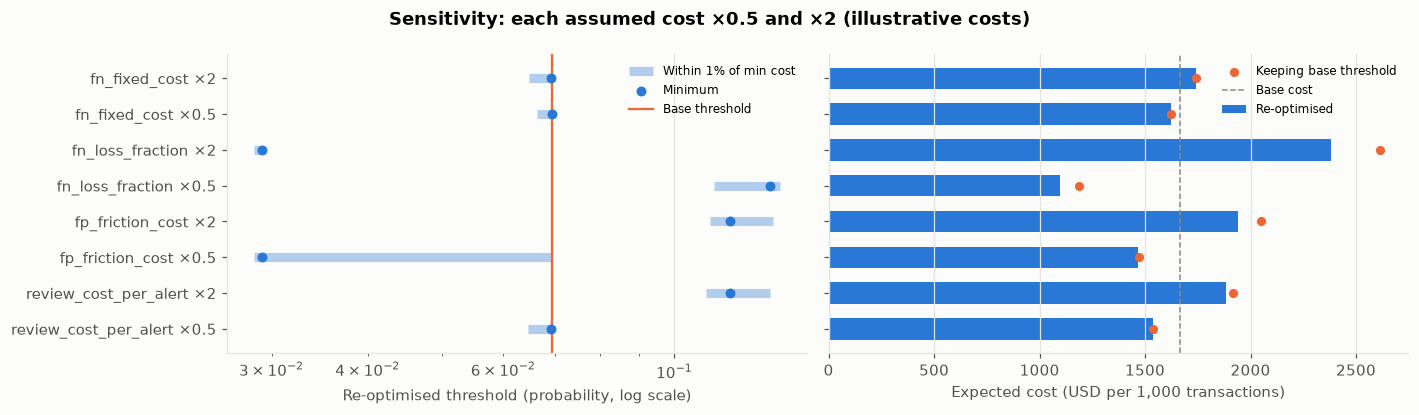

In [5]:
s = sens[sens["parameter"] != "(base)"].copy()
s["label"] = s["parameter"] + " ×" + s["factor"].map(lambda f: f"{f:g}")
base_row = sens[sens["parameter"] == "(base)"].iloc[0]
fig, axes = P.plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
yy = np.arange(len(s))
axes[0].hlines(
    yy,
    s["near_optimal_low"],
    s["near_optimal_high"],
    color=P.SERIES[0],
    lw=6,
    alpha=0.35,
    label=f"Within {100 * NEAR_OPTIMAL_TOL:.0f}% of min cost",
)
axes[0].scatter(s["best_threshold"], yy, color=P.SERIES[0], s=30, zorder=3, label="Minimum")
axes[0].axvline(base_row["best_threshold"], color=P.FRAUD, lw=1.5, label="Base threshold")
axes[0].set_xscale("log")
axes[0].set_xlabel("Re-optimised threshold (probability, log scale)")
axes[0].set_yticks(yy, s["label"])
axes[0].legend(fontsize=8)
axes[1].barh(yy, s["cost_per_1000_txn"], color=P.SERIES[0], height=0.6, label="Re-optimised")
axes[1].scatter(
    s["cost_per_1000_at_base_threshold"],
    yy,
    color=P.FRAUD,
    zorder=3,
    s=25,
    label="Keeping base threshold",
)
axes[1].axvline(base_row["cost_per_1000_txn"], color=P.NEUTRAL, ls="--", lw=1, label="Base cost")
axes[1].set_xlabel("Expected cost (USD per 1,000 transactions)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Sensitivity: each assumed cost ×0.5 and ×2 (illustrative costs)", fontweight="bold")
fig.tight_layout()
P.save(fig, "p2_cost_sensitivity")
P.plt.show()

## 3. Export for the website's threshold simulator

Cost is linear in the parameters, so per threshold the counts TP / FP / FN / TN and the USD amount
of missed fraud are enough for the browser to recompute cost for any values a visitor picks.

In [6]:
web = export_for_web(oof, web_grid([best["threshold"]]))
web.update(
    {
        "cost_label": COST_LABEL,
        "default_params": cost.numeric(),
        "chosen_threshold": best["threshold"],
        "sensitivity_factors": factors,
        "model": final_spec,
        "cv_pr_auc": metric_ci(final, "pr_auc"),
        "cv_roc_auc": metric_ci(final, "roc_auc"),
    }
)
write_json(web, "p2_threshold_web")
print(f"exported {len(web['threshold'])} thresholds")

exported 680 thresholds


## 4. Three-tier policy: approve / step-up / decline

Adds a second threshold above which a transaction is declined outright. Under the two-tier cost
model step-up stops every fraud, so declining could never be cheaper; the three-tier model
therefore also assumes a share of fraud gets through step-up (`stepup_fraud_pass_rate`). Both
policies are evaluated under that same model for a fair comparison. The decline-specific values
need Nat's approval before use (`configs/cost.yaml`, `three_tier.status`).

In [7]:
if three.usable:
    tt = choose_three_tier(oof, cost, three)
    write_json({"params": three.to_dict(), **tt, "cost_label": COST_LABEL}, "p2_three_tier")
    rows = []
    for name in ["stepup_fraud_pass_rate", "decline_fp_cost"]:
        for f in factors:
            q = replace(
                three,
                **{
                    name: min(
                        getattr(three, name) * f, 1.0 if name == "stepup_fraud_pass_rate" else 1e9
                    )
                },
            )
            r = choose_three_tier(oof, cost, q)
            rows.append(
                {
                    "parameter": name,
                    "factor": f,
                    "value": getattr(q, name),
                    "t_stepup": r["t_stepup"],
                    "t_decline": r["t_decline"],
                    "cost_per_1000_txn": r["cost_per_1000_txn"],
                    "two_tier_cost_per_1000": r["two_tier_same_model_cost_per_1000"],
                }
            )
    tt_sens = pd.DataFrame(rows)
    write_csv(tt_sens, "p2_three_tier_sensitivity")
    display(
        Markdown(
            f"Three-tier thresholds: step-up ≥ **{tt['t_stepup']:.4f}**, decline ≥ "
            f"**{tt['t_decline']:.4f}** → {tt['cost_per_1000_txn']:,.0f} USD per 1,000; two-tier under "
            f"the same assumptions: {tt['two_tier_same_model_cost_per_1000']:,.0f} USD per 1,000 "
            f"(threshold {tt['two_tier_same_model_threshold']:.4f}). _{COST_LABEL}._"
        )
    )
    display(tt_sens.round(4))
else:
    tt = None
    display(
        Markdown(
            f"**Pending:** three-tier values are `{three.status}`; this section runs once "
            "Nat accepts them."
        )
    )

**Pending:** three-tier values are `proposed`; this section runs once Nat accepts them.

## 5. The one-time holdout evaluation

The final pipeline is refit on all dev rows and scores the 4,000 holdout rows **once**, with the
threshold(s) fixed above. A lock file (`notes/holdout_lock.json`) records these choices; trying to
evaluate a different pipeline or threshold on the holdout raises an error. Intervals are
stratified bootstrap 95% CIs (2,000 resamples). With only 68 fraud cases they are wide.

In [8]:
if tt is not None:
    df_all = attach_splits(load_raw())
    hold = evaluate_holdout(
        df_all,
        final_spec,
        best["threshold"],
        cost,
        three_tier=(three, tt["t_stepup"], tt["t_decline"]),
        allow_create=True,
    )
    scores = hold.pop("_scores")
    write_json(hold, "p2_holdout")
    m = hold["metrics"]
    cv_ap, cv_roc = metric_ci(final, "pr_auc"), metric_ci(final, "roc_auc")
    comp = pd.DataFrame(
        [
            {
                "metric": "PR-AUC",
                "cv_dev": f"{cv_ap['mean']:.3f} [{cv_ap['ci_low']:.3f}, {cv_ap['ci_high']:.3f}]",
                "holdout": f"{m['pr_auc']['value']:.3f} [{m['pr_auc']['ci_low']:.3f}, {m['pr_auc']['ci_high']:.3f}]",
            },
            {
                "metric": "ROC-AUC",
                "cv_dev": f"{cv_roc['mean']:.3f} [{cv_roc['ci_low']:.3f}, {cv_roc['ci_high']:.3f}]",
                "holdout": f"{m['roc_auc']['value']:.3f} [{m['roc_auc']['ci_low']:.3f}, {m['roc_auc']['ci_high']:.3f}]",
            },
            {
                "metric": "Recall @ threshold",
                "cv_dev": f"{best['recall']:.3f}",
                "holdout": f"{m['recall']['value']:.3f} [{m['recall']['ci_low']:.3f}, {m['recall']['ci_high']:.3f}]",
            },
            {
                "metric": "Precision @ threshold",
                "cv_dev": f"{best['precision']:.3f}",
                "holdout": f"{m['precision']['value']:.3f} [{m['precision']['ci_low']:.3f}, {m['precision']['ci_high']:.3f}]",
            },
            {
                "metric": "Step-up rate",
                "cv_dev": f"{best['alert_rate']:.4f}",
                "holdout": f"{m['alert_rate']['value']:.4f} [{m['alert_rate']['ci_low']:.4f}, {m['alert_rate']['ci_high']:.4f}]",
            },
            {
                "metric": "Cost / 1,000 txn (USD, two-tier)",
                "cv_dev": f"{best['cost_per_1000_txn']:.0f}",
                "holdout": f"{m['cost_per_1000_txn']['value']:.0f} [{m['cost_per_1000_txn']['ci_low']:.0f}, {m['cost_per_1000_txn']['ci_high']:.0f}]",
            },
            {
                "metric": "Cost / 1,000 txn (USD, step-up nobody)",
                "cv_dev": f"{best['flag_nothing_cost_usd'] / n * 1000:.0f}",
                "holdout": f"{m['flag_nothing_cost_per_1000_txn']['value']:.0f} [{m['flag_nothing_cost_per_1000_txn']['ci_low']:.0f}, {m['flag_nothing_cost_per_1000_txn']['ci_high']:.0f}]",
            },
            {
                "metric": "Cost / 1,000 txn (USD, three-tier)",
                "cv_dev": f"{tt['cost_per_1000_txn']:.0f}",
                "holdout": f"{m['three_tier_cost_per_1000_txn']['value']:.0f} [{m['three_tier_cost_per_1000_txn']['ci_low']:.0f}, {m['three_tier_cost_per_1000_txn']['ci_high']:.0f}]",
            },
        ]
    )
    write_csv(comp, "p2_holdout_vs_cv")
    display(comp)
else:
    hold = None
    display(
        Markdown(
            "**Not run yet.** The holdout is scored once, after all thresholds (including "
            "the three-tier pair) are fixed on CV."
        )
    )

**Not run yet.** The holdout is scored once, after all thresholds (including the three-tier pair) are fixed on CV.

## Summary

In [9]:
sens_nb = sens[sens["parameter"] != "(base)"]
worst = sens_nb.loc[sens_nb["regret_per_1000_txn"].idxmax()]
thr_lo, thr_hi = sens_nb["best_threshold"].min(), sens_nb["best_threshold"].max()
lines = [
    f"- **Step-up threshold {best['threshold']:.4f}** (chosen on dev OOF): catches "
    f"{100 * best['recall']:.1f}% of fraud, {100 * best['precision']:.1f}% of step-ups are fraud, "
    f"{100 * best['alert_rate']:.2f}% of transactions stepped up; expected cost "
    f"{best['cost_per_1000_txn']:,.0f} USD per 1,000 transactions, "
    f"{100 * best['saving_vs_flag_nothing']:.1f}% below doing nothing. Per-repeat optima: "
    f"{min(best['best_threshold_per_repeat']):.4f}–{max(best['best_threshold_per_repeat']):.4f}.",
    f"- **Sensitivity (×0.5 / ×2 per parameter):** the best threshold ranges "
    f"{thr_lo:.4f}–{thr_hi:.4f}; the largest regret from keeping the base threshold is "
    f"{worst['regret_per_1000_txn']:.2f} USD per 1,000 (`{worst['parameter']}` ×{worst['factor']:g}).",
    f"- **Website export:** `reports/p2_threshold_web.json` ({len(web['threshold'])} thresholds).",
]
if tt is not None:
    lines.append(
        f"- **Three-tier:** step-up ≥ {tt['t_stepup']:.4f}, decline ≥ {tt['t_decline']:.4f}; "
        f"{tt['cost_per_1000_txn']:,.0f} vs {tt['two_tier_same_model_cost_per_1000']:,.0f} USD per "
        f"1,000 for two-tier under the same assumptions."
    )
if hold is not None:
    m = hold["metrics"]
    lines.append(
        f"- **Holdout (once, {hold['n_fraud']} fraud):** PR-AUC {m['pr_auc']['value']:.3f} "
        f"(95% CI {m['pr_auc']['ci_low']:.3f}–{m['pr_auc']['ci_high']:.3f}) vs CV "
        f"{metric_ci(final, 'pr_auc')['mean']:.3f}; recall {100 * m['recall']['value']:.1f}% "
        f"({100 * m['recall']['ci_low']:.1f}–{100 * m['recall']['ci_high']:.1f}%); cost "
        f"{m['cost_per_1000_txn']['value']:,.0f} USD per 1,000 "
        f"({m['cost_per_1000_txn']['ci_low']:,.0f}–{m['cost_per_1000_txn']['ci_high']:,.0f})."
    )
lines.append(f"- _{COST_LABEL}._")
display(Markdown("\n".join(lines)))

- **Step-up threshold 0.0695** (chosen on dev OOF): catches 69.5% of fraud, 23.5% of step-ups are fraud, 5.01% of transactions stepped up; expected cost 1,664 USD per 1,000 transactions, 47.6% below doing nothing. Per-repeat optima: 0.0673–0.0834.
- **Sensitivity (×0.5 / ×2 per parameter):** the best threshold ranges 0.0292–0.1334; the largest regret from keeping the base threshold is 232.10 USD per 1,000 (`fn_loss_fraction` ×2).
- **Website export:** `reports/p2_threshold_web.json` (680 thresholds).
- _Illustrative assumed costs (not bank data)._